In [15]:
import re
import os
import jpype
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.svm import LinearSVC
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import learning_curve
import nltk
from nltk.corpus import stopwords

ZEMBEREK_PATH="zemberek-full.jar"

In [16]:
os.environ["JAVA_HOME"]=r"C:\Program Files\Java\jdk-17"
if not jpype.isJVMStarted():
    jpype.startJVM(
        jpype.getDefaultJVMPath(),
        "-Xmx2g",
        f"-Djava.class.path={ZEMBEREK_PATH}",
        ignoreUnrecognized=True
    )

In [17]:
nltk.download('stopwords')
TurkishSentenceExtractor=jpype.JClass('zemberek.tokenization.TurkishSentenceExtractor')
TurkishMorphology=jpype.JClass('zemberek.morphology.TurkishMorphology')
TurkishSpellChecker=jpype.JClass('zemberek.normalization.TurkishSpellChecker')
TurkishTokenizer=jpype.JClass('zemberek.tokenization.TurkishTokenizer')

extractor=TurkishSentenceExtractor.DEFAULT
morphology=TurkishMorphology.createWithDefaults()
tokenizer=TurkishTokenizer.ALL
spell=TurkishSpellChecker(morphology)
stop_words=nltk.corpus.stopwords.words('turkish')
text_count=0

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\zynpe\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [18]:
def preprocess_text(text):
    if isinstance(text,list):
        if len(text)>0:
            text=text[0]
        else:
            return ''
        
    text=re.sub(r'\b\d+\b','',text)
    text=re.sub(r'[^\w\s]','',text)
    text=text.lower()
    
    tokens=tokenizer.tokenize(text)
    process_word=[]
    for token in tokens:
        word=str(token.getText())
        if word.isalpha() and word not in stop_words:
            analysis=morphology.analyze(word)
            analysis_list=list(analysis)
            if len(analysis_list)>0:
                best_analysis=analysis_list[0]
                proper_noun=str(best_analysis.getPos())
                if "ProperNoun" in proper_noun:
                    process_word.append(word)
                    continue
                lemmatization=str(best_analysis.getStems().get(0))
                if proper_noun=='Verb' and not word.startswith(lemmatization):
                    process_word.append(word)
                else:
                    process_word.append(lemmatization)
            else:
                process_word.append(word)
    return " ".join(process_word)

In [19]:
#ornek = "Yapay zeka algoritmaları Ankara'da geliştirildi."
#print(preprocess_text(ornek))

In [20]:
df=pd.read_csv('data/dataset.csv')
print(f'Toplam makale sayısı:{len(df)}')
display(df['category'].value_counts())
display(df.head(2))

Toplam makale sayısı:6430


category
tarih                   1498
saglik                  1497
bilgisayar_bilimleri    1495
finans                  1495
spor                     445
Name: count, dtype: int64

,category,journal,title,abstract
0,bilgisayar_bilimleri,adyujsci,Yansımalı Banach Uzaylarda Operatörlerin Çarpı...,Bu çalışmada iki problem incelenmiştir. Genel ...
1,bilgisayar_bilimleri,adyujsci,CMS Açık Veri ile Eğitici Higgs Çalışması,"Kompakt Müon Solenoid (CMS) Deneyi, CERN’in Bü..."


In [21]:
df['full_text']=df['title'].fillna('')+". "+df['abstract'].fillna('')
df['processed_text']=df['full_text'].apply(preprocess_text)
display(df[['full_text','processed_text']].head(2))

,full_text,processed_text
0,Yansımalı Banach Uzaylarda Operatörlerin Çarpı...,yansı banach uzay operatör çarpım surjektiv ss...
1,CMS Açık Veri ile Eğitici Higgs Çalışması. Kom...,cms açık veri eğit higgs çalış kompakt müon so...


In [22]:
x_train, x_test, y_train, y_test = train_test_split(df['processed_text'],df['category'],test_size=0.2,random_state=42)
vectorizer=TfidfVectorizer(ngram_range=(1,1),min_df=2, max_df=0.85, sublinear_tf=True)
x_train_vectorized=vectorizer.fit_transform(x_train)
x_test_vectorized=vectorizer.transform(x_test)

model=LogisticRegression(C=0.5, class_weight='balanced', random_state=42, max_iter=1000)
model.fit(x_train_vectorized, y_train)
y_pred=model.predict(x_test_vectorized)
accuracy=accuracy_score(y_test,y_pred)
print(f"Model Doğruluk Oranı %{accuracy * 100:.2f}\n")
print('SINIFLANDIRMA BAŞARI RAPORU: \n')
print(classification_report(y_test, y_pred,zero_division=0))

Model Doğruluk Oranı %91.68

SINIFLANDIRMA BAŞARI RAPORU: 

                      precision    recall  f1-score   support

bilgisayar_bilimleri       0.92      0.92      0.92       319
              finans       0.92      0.88      0.90       304
              saglik       0.95      0.92      0.94       296
                spor       0.81      0.95      0.88        82
               tarih       0.91      0.95      0.93       285

            accuracy                           0.92      1286
           macro avg       0.90      0.92      0.91      1286
        weighted avg       0.92      0.92      0.92      1286



In [23]:
ornek="""Derin Öğrenme Modelleri Kullanılarak Türkçe Doğal Dil İşleme Süreçlerinde Duygu Analizi ve Sınıflandırma Başarısının Artırılması. Bu çalışmada, sosyal medya verileri ve akademik makaleler üzerinde duygu analizi yapmak amacıyla önişleme adımları ve transformer tabanlı derin öğrenme mimarileri (BERT, RoBERTa) karşılaştırmalı olarak incelenmiştir. Elde edilen deneysel sonuçlar, kelime vektör uzayı optimizasyonlarının ve dikkat mekanizmalarının metin sınıflandırma doğruluğunu önemli ölçüde artırdığını ve kategorik hata oranlarını minimum seviyeye indirdiğini göstermektedir."""
islenen_ornek=[preprocess_text(ornek)]
ornek_vectorized=vectorizer.transform(islenen_ornek)
tahmin=model.predict(ornek_vectorized)
skorlar = model.decision_function(ornek_vectorized)
for sinif, skor in zip(model.classes_, skorlar[0]):
    print(f"{sinif} -> Skor: {skor:.4f}")

feature_names = vectorizer.get_feature_names_out()
non_zero_indices = ornek_vectorized.nonzero()[1]

print("Modelin metinde yakaladığı kelimeler ve TF-IDF ağırlıkları:\n")
for idx in non_zero_indices:
    kelime = feature_names[idx]
    agirlik = ornek_vectorized[0, idx]
    print(f"- {kelime}: {agirlik:.4f}")
print(f"Test Edilen Cümle: '{ornek}'")
print(f"Modelin tahmini kategorisi: {tahmin[0]}")

bilgisayar_bilimleri -> Skor: 2.3135
finans -> Skor: -0.0676
saglik -> Skor: -0.4635
spor -> Skor: -1.0395
tarih -> Skor: -0.7429
Modelin metinde yakaladığı kelimeler ve TF-IDF ağırlıkları:

- adım: 0.1819
- akademik: 0.1454
- amac: 0.0679
- analiz: 0.1095
- artır: 0.1887
- başarı: 0.1098
- bert: 0.2295
- deney: 0.1126
- derin: 0.2398
- dikkat: 0.1038
- dil: 0.1345
- doğal: 0.1345
- doğru: 0.0975
- duygu: 0.2570
- ed: 0.0438
- el: 0.0694
- göster: 0.0672
- hata: 0.1383
- ince: 0.0702
- indir: 0.1719
- karşılaştır: 0.0887
- kategorik: 0.2144
- kelim: 0.1839
- kullan: 0.0551
- makale: 0.0984
- medya: 0.1511
- mekanizma: 0.1309
- metin: 0.1564
- mimari: 0.1741
- minimum: 0.1674
- model: 0.0907
- optimizasyon: 0.1525
- oran: 0.0989
- seviye: 0.1143
- sonuçla: 0.0971
- sosyal: 0.1051
- süreç: 0.1038
- sınıf: 0.1818
- taban: 0.1273
- transformer: 0.2501
- türk: 0.0954
- uzay: 0.1692
- vektör: 0.1668
- veri: 0.0732
- yap: 0.0607
- çalış: 0.0384
- ölçü: 0.1065
- önem: 0.0611
- öğren: 0.2290
- 

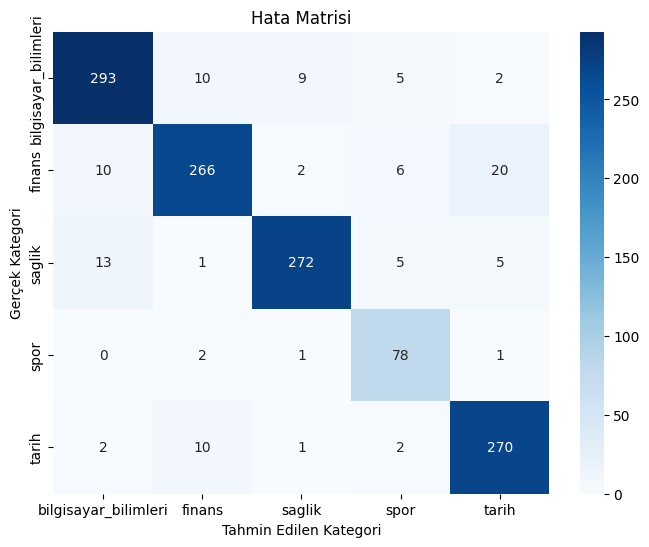

In [24]:
y_pred = model.predict(x_test_vectorized)
cm = confusion_matrix(y_test, y_pred, labels=model.classes_)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=model.classes_, 
            yticklabels=model.classes_)
plt.title('Hata Matrisi')
plt.xlabel('Tahmin Edilen Kategori')
plt.ylabel('Gerçek Kategori')
plt.show()

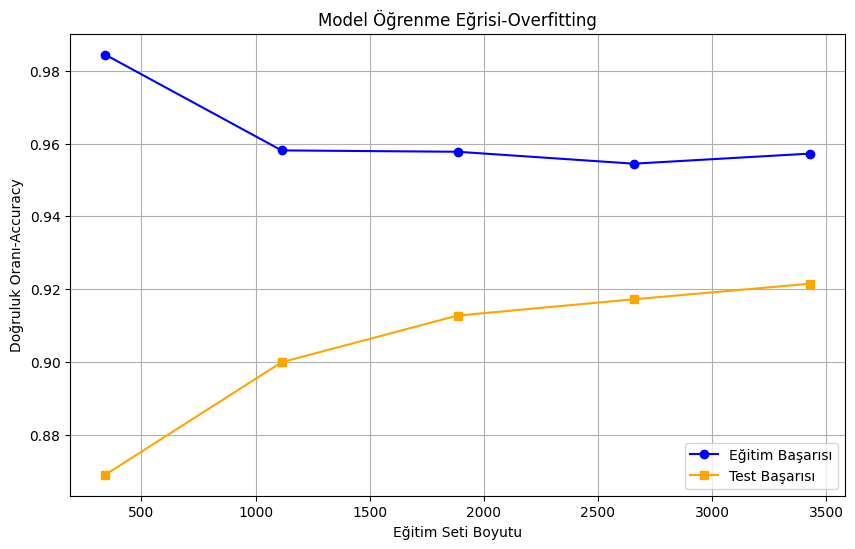

In [25]:
train_sizes, train_scores, test_scores = learning_curve(
    model,x_train_vectorized,y_train,cv=3,scoring='accuracy',train_sizes=np.linspace(0.1, 1.0, 5), n_jobs=1
)
train_mean = np.mean(train_scores, axis=1)
test_mean = np.mean(test_scores, axis=1)

plt.figure(figsize=(10,6))
plt.plot(train_sizes, train_mean, label='Eğitim Başarısı', marker='o', color='blue')
plt.plot(train_sizes, test_mean, label='Test Başarısı', marker='s', color='orange')

plt.title('Model Öğrenme Eğrisi-Overfitting')
plt.xlabel('Eğitim Seti Boyutu')
plt.ylabel('Doğruluk Oranı-Accuracy')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

In [14]:
ornek="""Enflasyon Oranlarının ve Döviz Kuru Dalgalanmalarının Borsa Piyasası Üzerindeki Etkisi. Bu araştırmada, makroekonomik değişkenlerden biri olan enflasyon ve döviz kurlarındaki hareketliliğin sermaye piyasaları ve hisse senedi getiri oranları üzerindeki yansımaları ampirik yöntemlerle analiz edilmiştir. Sonuçlar, yüksek enflasyon dönemlerinde yatırımcıların portföylerini korumak amacıyla alternatif finansal araçlara yöneldiğini göstermektedir."""
islenen_ornek=[preprocess_text(ornek)]
ornek_vectorized=vectorizer.transform(islenen_ornek)
tahmin=model.predict(ornek_vectorized)
skorlar = model.decision_function(ornek_vectorized)
for sinif, skor in zip(model.classes_, skorlar[0]):
    print(f"{sinif} -> Skor: {skor:.4f}")

feature_names = vectorizer.get_feature_names_out()
non_zero_indices = ornek_vectorized.nonzero()[1]

print("Modelin metinde yakaladığı kelimeler ve TF-IDF ağırlıkları:\n")
for idx in non_zero_indices:
    kelime = feature_names[idx]
    agirlik = ornek_vectorized[0, idx]
    print(f"- {kelime}: {agirlik:.4f}")
print(f"Test Edilen Cümle: '{ornek}'")
print(f"Modelin tahmini kategorisi: {tahmin[0]}")

bilgisayar_bilimleri -> Skor: -0.4240
finans -> Skor: 3.1428
saglik -> Skor: -0.6056
spor -> Skor: -1.2953
tarih -> Skor: -0.8179
Modelin metinde yakaladığı kelimeler ve TF-IDF ağırlıkları:

- alternatif: 0.1463
- amac: 0.0790
- ampirik: 0.1813
- analiz: 0.0751
- araç: 0.1390
- araştırma: 0.1018
- borsa: 0.1740
- dalgalan: 0.1999
- değişken: 0.1234
- dönem: 0.1094
- döviz: 0.3157
- ed: 0.0509
- enflasyon: 0.3868
- etki: 0.0734
- finansal: 0.1379
- getiri: 0.1838
- göster: 0.0781
- hareket: 0.1200
- hiss: 0.1912
- koru: 0.1307
- kur: 0.1065
- kuru: 0.1760
- makroekonomik: 0.2071
- oran: 0.1947
- piyasa: 0.2378
- portföy: 0.2092
- sened: 0.2024
- sermaye: 0.1438
- sonuçla: 0.1128
- yansı: 0.1437
- yatırım: 0.1661
- yönel: 0.1848
- yöntem: 0.0747
- yüksek: 0.0882
- üzer: 0.1701
Test Edilen Cümle: 'Enflasyon Oranlarının ve Döviz Kuru Dalgalanmalarının Borsa Piyasası Üzerindeki Etkisi. Bu araştırmada, makroekonomik değişkenlerden biri olan enflasyon ve döviz kurlarındaki hareketliliğin serm

In [15]:
ornek="""Tip 2 Diyabet Hastalarında Farmakolojik Tedaviye Ek Olarak Uygulanan Diyet Programlarının Glisemik Kontrole Etkisi. Bu klinik çalışmada, tip 2 diyabet tanısı konulmuş hastaların kan glikoz düzeylerinin düzenlenmesinde tıbbi beslenme tedavisinin ve diyet uyumunun önemi değerlendirilmiştir. Araştırma sonucunda, hastaların metabolik parametrelerinin iyileşmesinde ve HbA1c seviyelerinin düşürülmesinde bireyselleştirilmiş diyet programlarının kritik bir rol oynadığı tespit edilmiştir."""
islenen_ornek=[preprocess_text(ornek)]
ornek_vectorized=vectorizer.transform(islenen_ornek)
tahmin=model.predict(ornek_vectorized)
skorlar = model.decision_function(ornek_vectorized)
for sinif, skor in zip(model.classes_, skorlar[0]):
    print(f"{sinif} -> Skor: {skor:.4f}")

feature_names = vectorizer.get_feature_names_out()
non_zero_indices = ornek_vectorized.nonzero()[1]

print("Modelin metinde yakaladığı kelimeler ve TF-IDF ağırlıkları:\n")
for idx in non_zero_indices:
    kelime = feature_names[idx]
    agirlik = ornek_vectorized[0, idx]
    print(f"- {kelime}: {agirlik:.4f}")
print(f"Test Edilen Cümle: '{ornek}'")
print(f"Modelin tahmini kategorisi: {tahmin[0]}")

bilgisayar_bilimleri -> Skor: -0.0089
finans -> Skor: -0.7448
saglik -> Skor: 2.7245
spor -> Skor: -0.6142
tarih -> Skor: -1.3566
Modelin metinde yakaladığı kelimeler ve TF-IDF ağırlıkları:

- araştır: 0.0770
- besle: 0.1586
- bir: 0.0409
- bireysel: 0.1536
- değerlendir: 0.0729
- diyabet: 0.3258
- diyet: 0.4286
- düzenle: 0.1177
- düzey: 0.0947
- düşür: 0.1638
- ed: 0.0468
- ek: 0.1207
- etki: 0.0675
- farmakolojik: 0.2143
- glikoz: 0.2405
- glisemik: 0.2454
- hasta: 0.1984
- iyi: 0.0978
- kan: 0.1370
- klinik: 0.1204
- kon: 0.1188
- kontrol: 0.1096
- kritik: 0.1431
- metabolik: 0.1887
- oyna: 0.1317
- parametre: 0.1217
- program: 0.1925
- rol: 0.1074
- seviye: 0.1222
- sonuc: 0.0842
- tanı: 0.1052
- tedavi: 0.1771
- tespit: 0.0890
- tip: 0.2084
- tıbbi: 0.1583
- uygula: 0.0706
- uyum: 0.1289
- çalış: 0.0410
- önem: 0.0653
Test Edilen Cümle: 'Tip 2 Diyabet Hastalarında Farmakolojik Tedaviye Ek Olarak Uygulanan Diyet Programlarının Glisemik Kontrole Etkisi. Bu klinik çalışmada, tip 2 d

In [16]:
ornek="""Profesyonel Futbolcularda Maç İçi Yüksek Şiddetli Koşu Performanslarının Sezon İçindeki Değişimi. Bu çalışmada, profesyonel futbol liginde forma giyen sporcuların müsabaka esnasındaki aerobik ve anaerobik performans parametreleri GPS takip sistemleri aracılığıyla incelenmiştir. Elde edilen bulgular, oyuncuların yüksek şiddetli koçluk reaksiyonlarının ve sprint mesafelerinin maçın dakikalarına göre nasıl değiştiğini ve antrenman yüklerinin performans üzerindeki doğrudan etkilerini ortaya koymaktadır."""
islenen_ornek=[preprocess_text(ornek)]
ornek_vectorized=vectorizer.transform(islenen_ornek)
tahmin=model.predict(ornek_vectorized)
skorlar = model.decision_function(ornek_vectorized)
for sinif, skor in zip(model.classes_, skorlar[0]):
    print(f"{sinif} -> Skor: {skor:.4f}")

feature_names = vectorizer.get_feature_names_out()
non_zero_indices = ornek_vectorized.nonzero()[1]

print("Modelin metinde yakaladığı kelimeler ve TF-IDF ağırlıkları:\n")
for idx in non_zero_indices:
    kelime = feature_names[idx]
    agirlik = ornek_vectorized[0, idx]
    print(f"- {kelime}: {agirlik:.4f}")
print(f"Test Edilen Cümle: '{ornek}'")
print(f"Modelin tahmini kategorisi: {tahmin[0]}")

bilgisayar_bilimleri -> Skor: 0.4491
finans -> Skor: -0.5062
saglik -> Skor: -0.3751
spor -> Skor: 1.7081
tarih -> Skor: -1.2760
Modelin metinde yakaladığı kelimeler ve TF-IDF ağırlıkları:

- aerobik: 0.1705
- anaerobik: 0.1631
- antrenman: 0.1539
- aracılığıyla: 0.1271
- bulgula: 0.0884
- dakika: 0.1422
- değiş: 0.0964
- değişim: 0.0998
- doğrudan: 0.1217
- ed: 0.0408
- el: 0.0647
- esna: 0.2061
- etki: 0.0588
- form: 0.1083
- futbol: 0.2482
- giy: 0.2190
- gps: 0.2190
- göre: 0.0663
- ince: 0.0655
- koy: 0.0888
- koç: 0.2140
- koşu: 0.1781
- lig: 0.1687
- maç: 0.3085
- mesafe: 0.1450
- müsabaka: 0.1653
- orta: 0.0620
- oyun: 0.1572
- parametre: 0.1061
- performans: 0.2026
- profesyonel: 0.2579
- reaksiyon: 0.1402
- sezon: 0.1735
- sistem: 0.0826
- sporcu: 0.1335
- sprint: 0.1927
- takip: 0.1128
- yük: 0.1302
- yüksek: 0.1198
- çalış: 0.0358
- üzer: 0.0806
- şiddet: 0.2113
Test Edilen Cümle: 'Profesyonel Futbolcularda Maç İçi Yüksek Şiddetli Koşu Performanslarının Sezon İçindeki Değiş

In [17]:
ornek="""Osmanlı Devleti’nin Son Döneminde Taşra Teşkilatında Yapılan İdari Reformlar ve Vergi Toplama Mekanizmaları
Bu araştırmada, 19. yüzyılın ikinci yarısında merkezi otoriteyi güçlendirmek amacıyla hayata geçirilen idari ve mali düzenlemelerin Anadolu'daki yansımaları birinci el arşiv belgeleri ışığında incelenmiştir. Dönemin salnameleri ve şer'iye sicilleri taranarak, mukataa gelirlerinin dönüşümü, vergi muafiyetleri ve yerel idarecilerin merkezi hükümetle olan ilişkileri tarihsel eleştiri yöntemiyle analiz edilmiştir. Elde edilen bulgular, tanzimat sonrası bürokratik dönüşümün kırsal kesimdeki sosyo-ekonomik yapılara etkilerini aydınlatmaktadır."""
islenen_ornek=[preprocess_text(ornek)]
ornek_vectorized=vectorizer.transform(islenen_ornek)
tahmin=model.predict(ornek_vectorized)
skorlar = model.decision_function(ornek_vectorized)
for sinif, skor in zip(model.classes_, skorlar[0]):
    print(f"{sinif} -> Skor: {skor:.4f}")

feature_names = vectorizer.get_feature_names_out()
non_zero_indices = ornek_vectorized.nonzero()[1]

print("Modelin metinde yakaladığı kelimeler ve TF-IDF ağırlıkları:\n")
for idx in non_zero_indices:
    kelime = feature_names[idx]
    agirlik = ornek_vectorized[0, idx]
    print(f"- {kelime}: {agirlik:.4f}")
print(f"Test Edilen Cümle: '{ornek}'")
print(f"Modelin tahmini kategorisi: {tahmin[0]}")

bilgisayar_bilimleri -> Skor: -0.4275
finans -> Skor: 0.5797
saglik -> Skor: -0.6084
spor -> Skor: -1.0664
tarih -> Skor: 1.5226
Modelin metinde yakaladığı kelimeler ve TF-IDF ağırlıkları:

- amac: 0.0631
- anadolu: 0.1453
- analiz: 0.0601
- araştırma: 0.0814
- arşiv: 0.1255
- aydınlat: 0.1514
- belge: 0.1289
- birinci: 0.1111
- bulgula: 0.0881
- bürokratik: 0.1881
- devlet: 0.0905
- döne: 0.0807
- dönem: 0.0875
- dönüşüm: 0.1861
- düzenle: 0.1023
- ed: 0.0689
- el: 0.1092
- eleştiri: 0.1404
- etki: 0.0586
- gelir: 0.1446
- geçir: 0.1113
- güçlen: 0.1391
- hayat: 0.1054
- hükümet: 0.1309
- idare: 0.1491
- idari: 0.1585
- ikinci: 0.1138
- ilişki: 0.0706
- ince: 0.0652
- kes: 0.1351
- kır: 0.1359
- mali: 0.1373
- mekanizma: 0.1216
- merkezi: 0.2216
- muafiyet: 0.2324
- osmanlı: 0.1030
- otorite: 0.1618
- reform: 0.1435
- sicil: 0.2245
- son: 0.0771
- sonra: 0.0673
- sosyoekonomik: 0.1561
- tanzimat: 0.1816
- tara: 0.1106
- tarih: 0.0816
- taşra: 0.1942
- teşkilat: 0.1664
- topla: 0.1263


In [5]:
df=pd.read_csv('data2/dataset.csv')
print(f'Toplam makale sayısı:{len(df)}')
display(df['category'].value_counts())
display(df.head(2))

Toplam makale sayısı:8635


category
bilgisayar_bilimleri    2658
saglik                  2369
tarih                   1670
finans                  1493
spor                     445
Name: count, dtype: int64

,category,journal,title,abstract
0,bilgisayar_bilimleri,adyujsci,Yansımalı Banach Uzaylarda Operatörlerin Çarpı...,Bu çalışmada iki problem incelenmiştir. Genel ...
1,bilgisayar_bilimleri,adyujsci,CMS Açık Veri ile Eğitici Higgs Çalışması,"Kompakt Müon Solenoid (CMS) Deneyi, CERN’in Bü..."


In [6]:
df['full_text']=df['title'].fillna('')+". "+df['abstract'].fillna('')
df['processed_text']=df['full_text'].apply(preprocess_text)
display(df[['full_text','processed_text']].head(2))

,full_text,processed_text
0,Yansımalı Banach Uzaylarda Operatörlerin Çarpı...,yansı banach uzay operatör çarpım surjektiv ss...
1,CMS Açık Veri ile Eğitici Higgs Çalışması. Kom...,cms açık veri eğit higgs çalış kompakt müon so...


In [7]:
x_train, x_test, y_train, y_test = train_test_split(df['processed_text'],df['category'],test_size=0.2,random_state=42)
vectorizer=TfidfVectorizer(ngram_range=(1,1),min_df=2, max_df=0.85, sublinear_tf=True)
x_train_vectorized=vectorizer.fit_transform(x_train)
x_test_vectorized=vectorizer.transform(x_test)

model=LogisticRegression(C=0.5, class_weight='balanced', random_state=42, max_iter=1000)
model.fit(x_train_vectorized, y_train)
y_pred=model.predict(x_test_vectorized)
accuracy=accuracy_score(y_test,y_pred)
print(f"Model Doğruluk Oranı %{accuracy * 100:.2f}\n")
print('SINIFLANDIRMA BAŞARI RAPORU: \n')
print(classification_report(y_test, y_pred,zero_division=0))

Model Doğruluk Oranı %92.53

SINIFLANDIRMA BAŞARI RAPORU: 

                      precision    recall  f1-score   support

bilgisayar_bilimleri       0.95      0.93      0.94       535
              finans       0.89      0.85      0.87       294
              saglik       0.96      0.94      0.95       482
                spor       0.86      0.90      0.88        80
               tarih       0.90      0.96      0.93       336

            accuracy                           0.93      1727
           macro avg       0.91      0.92      0.91      1727
        weighted avg       0.93      0.93      0.93      1727



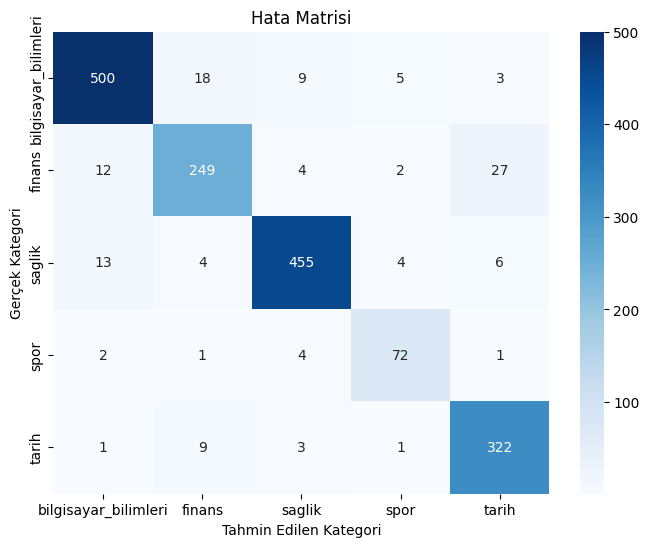

In [8]:
y_pred = model.predict(x_test_vectorized)
cm = confusion_matrix(y_test, y_pred, labels=model.classes_)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=model.classes_, 
            yticklabels=model.classes_)
plt.title('Hata Matrisi')
plt.xlabel('Tahmin Edilen Kategori')
plt.ylabel('Gerçek Kategori')
plt.show()

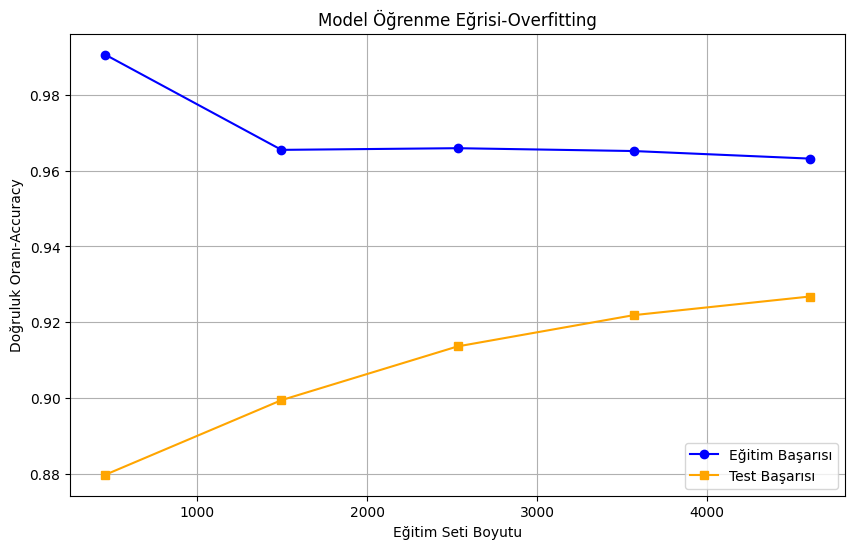

In [9]:
train_sizes, train_scores, test_scores = learning_curve(
    model,x_train_vectorized,y_train,cv=3,scoring='accuracy',train_sizes=np.linspace(0.1, 1.0, 5), n_jobs=1
)
train_mean = np.mean(train_scores, axis=1)
test_mean = np.mean(test_scores, axis=1)

plt.figure(figsize=(10,6))
plt.plot(train_sizes, train_mean, label='Eğitim Başarısı', marker='o', color='blue')
plt.plot(train_sizes, test_mean, label='Test Başarısı', marker='s', color='orange')

plt.title('Model Öğrenme Eğrisi-Overfitting')
plt.xlabel('Eğitim Seti Boyutu')
plt.ylabel('Doğruluk Oranı-Accuracy')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

In [1]:
import sys
print(sys.maxsize>232)

True


In [14]:
ornek="""Birçok memeli türünde dil papillalarının morfolojikyapısı ile ilgili çalışma yapılmasına rağmen, insanfetuslarında dil papillalarının gelişimi detaylı şekildeincelenmemiştir. Bu çalışmanın amacı taramalı elektronmikroskobu ile insan fetuslarında dil papillalarınıngelişimini ve morfolojik gelişimini incelemektir. Buamaçla, yaşları üç ile sekiz ay arasında değişen 24 adetinsan fetusunun dillerinden doku örnekleri alındı.Formalin ile tespit edilmiş fetusların dilleri taramalıelektron mikroskopi için rutin işlemlerden geçirilerekincelendi.Bütün çalışma dönemlerinde, filiform, fungiform vesirkumvallat papillalar gözlendi. Dokuzuncu hafta başındafungiform papillaların ilk taslakları filiform vesirkumvallat papillalarınkinden daha erken görüldü.Fungiform papilla yuvarlak şekilliydi ve dilin önündedaha fazla dağılım göstermişti. Filiform papilla dilinbütün dorsal yüzeyinde fungiform papillaların arasınadağılmış, kabartılar halinde gözlenmekteydi. Sirkumvallatpapillalar ise dokuzuncu hafta sonunda filiform papillalarile birlikte gözlenmeye başlamıştı. Bu papillalar daireşeklindeydi ve bunların her biri bir olukla çevrelenmişti.Papillalar üzerindeki epitel belirgin şekildegözlenmekteydi. Keratinizasyon beşinci ayda papillalarüzerinde pulsu yapılar şeklinde ortaya çıkmıştı. Birinci veikinci trimesterde tüm papillalar hacimce ve morfolojikolarak gelişimlerine devam etmekle birlikte ancak üçüncütrimesterin sonunda sirkumvallat papillalar yetişkinformuna benzer şekil almıştı.Taramalı elektron mikroskobik çalışma insan dil gelişimisırasında gelişen olayların geçici ve birbirini izleyenyapısını belirlemiştir. Bu çalışmadan elde edilen sonuçlar,insan fetusunda gelişmekte olan dil papillalarınınmorfolojik bilgilerine ek katkı sağlamıştır.
"""
islenen_ornek=[preprocess_text(ornek)]
ornek_vectorized=vectorizer.transform(islenen_ornek)
tahmin=model.predict(ornek_vectorized)
skorlar = model.decision_function(ornek_vectorized)
for sinif, skor in zip(model.classes_, skorlar[0]):
    print(f"{sinif} -> Skor: {skor:.4f}")

feature_names = vectorizer.get_feature_names_out()
non_zero_indices = ornek_vectorized.nonzero()[1]

print("Modelin metinde yakaladığı kelimeler ve TF-IDF ağırlıkları:\n")
for idx in non_zero_indices:
    kelime = feature_names[idx]
    agirlik = ornek_vectorized[0, idx]
    print(f"- {kelime}: {agirlik:.4f}")
print(f"Test Edilen Cümle: '{ornek}'")
print(f"Modelin tahmini kategorisi: {tahmin[0]}")

bilgisayar_bilimleri -> Skor: 0.6762
finans -> Skor: -0.1523
saglik -> Skor: 0.4267
spor -> Skor: -0.9874
tarih -> Skor: 0.0368
Modelin metinde yakaladığı kelimeler ve TF-IDF ağırlıkları:

- amac: 0.0461
- ancak: 0.0636
- ara: 0.0391
- ay: 0.1505
- başla: 0.0677
- belirgin: 0.0952
- belirle: 0.0452
- benzer: 0.0909
- beşinci: 0.1365
- bilgi: 0.0602
- bir: 0.0272
- birbiri: 0.0963
- birinci: 0.0859
- birlikte: 0.1044
- birçok: 0.0725
- bu: 0.0603
- buamaçla: 0.1576
- dağılım: 0.0820
- detay: 0.1015
- devam: 0.0818
- değiş: 0.0714
- dil: 0.2897
- doku: 0.0983
- dokuzuncu: 0.2373
- dorsal: 0.1803
- dönem: 0.0681
- ed: 0.0518
- ek: 0.0783
- el: 0.0476
- elektro: 0.1004
- epitel: 0.1576
- erken: 0.0894
- et: 0.0490
- fazla: 0.0689
- geliş: 0.1078
- gelişim: 0.1708
- geçici: 0.1240
- göster: 0.0480
- gözle: 0.1659
- haci: 0.1203
- hafta: 0.1593
- hal: 0.0676
- ilgili: 0.0643
- ilk: 0.0650
- incele: 0.0677
- insan: 0.1326
- işlem: 0.0757
- katkı: 0.0704
- memeli: 0.1697
- mikroskobik: 0.1485
